# Coupling topologies

Every ansatz with two-qubit gates has to decide **which pairs of qubits it couples**. In mpstab that choice is a graph, a `Topology`, passed to the ansatz through its `graph` field. In this tutorial you will learn how to:

- build topologies: named lattices, a list of edges, the coupling map of a device;
- place the same ansatz on different graphs;
- see that, at fixed magic, the graph decides how hard the circuit is for HSMPO;
- build an ansatz on the coupling map of a device and check that it fits there.

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import networkx as nx
from qibo.config import log

from mpstab import HSMPO, Topology
from mpstab.models.ansatze import HardwareEfficient, RampedKickedIsing
sys.path.append("../..")  # examples/, home of the plot style
from plotting import COLORS, set_style

log.setLevel("WARNING")  # silence qibo's backend message
set_style()

## What a topology is

A `Topology` is a graph on the qubits $0, 1, \dots, n-1$, stored as an **ordered** list of edges: an ansatz places its gates in that order. The simplest way to get one is by name. `"grid"` picks the most square rectangle that holds the qubits, here $3 \times 4$.

In [2]:
grid = Topology.named("grid", 12)
print(grid.name)
print(grid.edges)

grid:3x4
((0, 1), (2, 3), (4, 5), (6, 7), (8, 9), (10, 11), (0, 4), (1, 5), (2, 6), (3, 7), (1, 2), (5, 6), (9, 10), (4, 8), (5, 9), (6, 10), (7, 11))


Two gates on disjoint pairs can run at the same time. `layers` groups the edges into such layers of disjoint bonds, and `depth` counts them: it is the two-qubit depth of one pass over the graph. A chain needs 2 layers (even bonds, then odd bonds), a grid 4, a star one per leaf, since every bond touches the hub.

In [3]:
for name in ["chain", "ring", "star", "grid", "complete"]:
    topology = Topology.named(name, 12)
    print(f"{name:>8}: {len(topology):>2} edges, depth {topology.depth:>2}, max degree "
          f"{max(topology.degree(q) for q in range(12))}")

   chain: 11 edges, depth  2, max degree 2
    ring: 12 edges, depth  2, max degree 2
    star: 11 edges, depth 11, max degree 11
    grid: 17 edges, depth  4, max degree 4
complete: 66 edges, depth 11, max degree 11


To see them, `to_networkx` turns a topology into a `networkx` graph. The helper below draws one: qubits on a circle, the hub of the star in the middle and the grid row by row.

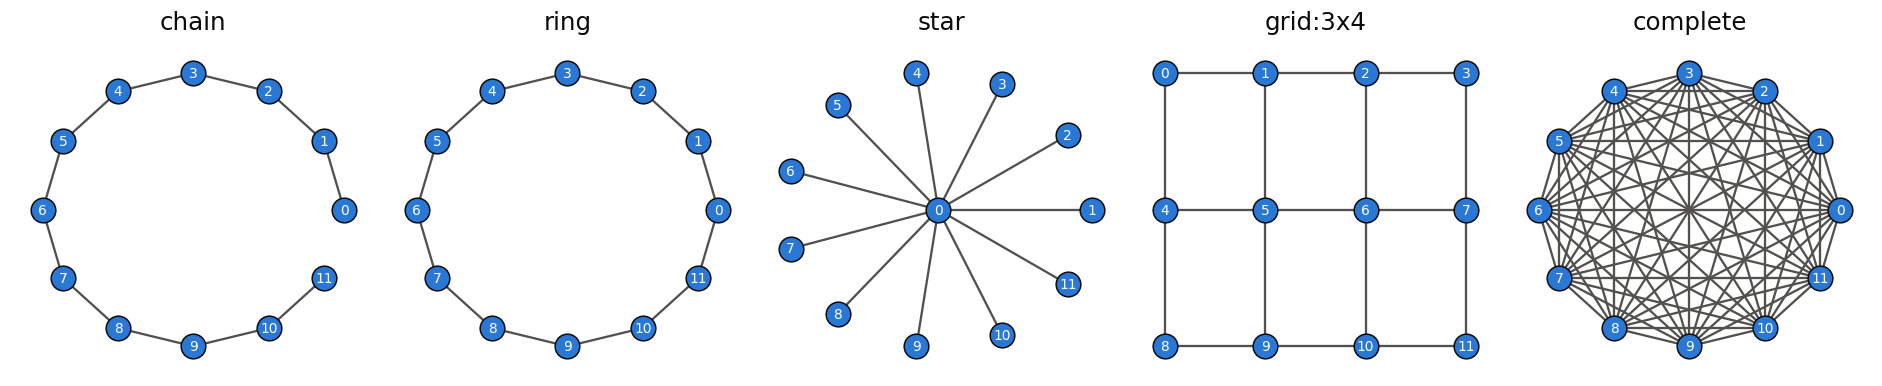

In [4]:
def draw(topology, ax, pos=None):
    graph = topology.to_networkx()
    if pos is None:
        pos = nx.circular_layout(graph)
    nx.draw_networkx_edges(graph, pos, ax=ax, edge_color=COLORS["gray"], width=1.5)
    nx.draw_networkx_nodes(graph, pos, ax=ax, node_color=COLORS["blue"],
                           edgecolors=COLORS["black"], node_size=260)
    nx.draw_networkx_labels(graph, pos, ax=ax, font_color="white", font_size=9)
    ax.set_title(topology.name or "custom")
    ax.set_axis_off()


circle = nx.circular_layout(range(1, 12))
layouts = {
    "star": {0: (0, 0), **circle},
    "grid": {q: (q % 4, -(q // 4)) for q in range(12)},
}
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, name in zip(axes, ["chain", "ring", "star", "grid", "complete"]):
    draw(Topology.named(name, 12), ax, layouts.get(name))
plt.show()

A topology can also be built from a list of edges, kept as written, or from any `networkx` or `rustworkx` graph.

In [5]:
custom = Topology.from_edges([(0, 1), (1, 2), (2, 0), (2, 3)])
print(custom.nqubits, custom.edges, custom.depth)

4 ((0, 1), (1, 2), (2, 0), (2, 3)) 3


## The same ansatz on different graphs

Every ansatz with couplings takes `graph`: a name, a list of edges, a graph or a `Topology`. The single-qubit gates stay the same; the two-qubit gates go on the edges, layer by layer. Here is `RampedKickedIsing`, a kicked Ising chain near a Clifford point, on the $3 \times 4$ grid.

In [6]:
ansatz = RampedKickedIsing(nqubits=12, n_steps=3, delta_h=0.2, graph="grid")
print(f"edges per step: {len(ansatz.edges)}, layers per step: {ansatz.coupling_depth}")

edges per step: 17, layers per step: 4


`ansatz.topology` reads the pairs back from the circuit itself: the pairs its gates actually couple. With every bond kept it is the grid again. With `bond_density` below 1, each coupling is kept with that probability, and `ansatz.topology` shows which bonds survived.

In [7]:
print(ansatz.topology.is_subgraph_of(grid), len(ansatz.topology))

diluted = RampedKickedIsing(nqubits=12, n_steps=1, delta_h=0.2, graph="grid",
                            bond_density=0.5, seed=1)
print(f"{len(diluted.topology)} of {len(diluted.edges)} bonds kept")

True 17
12 of 17 bonds kept


Without a `graph`, every ansatz keeps its usual pattern, gate for gate. `ansatz.topology` works there too: `HardwareEfficient` couples its qubits in a ring.

In [8]:
print(HardwareEfficient(nqubits=6).topology.edges)

((0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0))


## The graph decides the cost

HSMPO keeps the Clifford part of a circuit in a stabilizer tableau, for free, and only the magic gates in an MPS. Each magic gate enters the MPS as a Pauli rotation, *dressed* by the Clifford gates before it, and how far that Pauli spreads depends on the couplings. So the graph changes the cost of the simulation even at fixed magic.

We run the same `RampedKickedIsing` on 12 qubits, with the same magic (`delta_h = 0.2`), on four graphs, and record the largest bond dimension of the MPS after each number of steps. Nothing is truncated: on 12 qubits the bond dimension can reach $2^6 = 64$.

In [9]:
graphs = ["chain", "ring", "grid", "complete"]
steps = range(1, 6)
bond = {}
for graph in graphs:
    bond[graph] = [
        HSMPO(RampedKickedIsing(nqubits=12, n_steps=n, delta_h=0.2, seed=0, graph=graph),
              progress=False).original_circuit_mps.max_bond()
        for n in steps
    ]
    print(f"{graph:>8}: {bond[graph]}")

   chain: [1, 4, 16, 59, 61]


    ring: [1, 16, 60, 63, 56]


    grid: [1, 64, 64, 64, 64]


complete: [1, 4, 7, 5, 5]


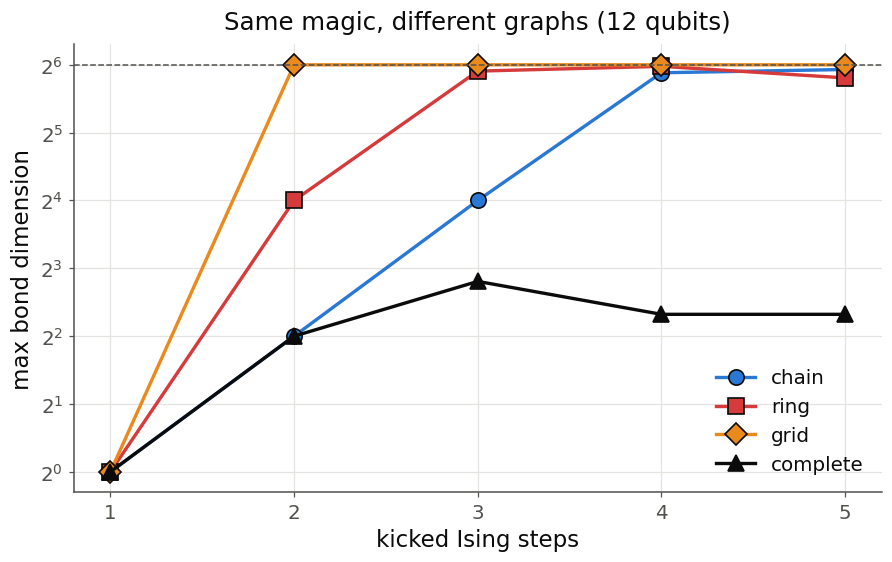

In [10]:
fig, ax = plt.subplots()
markers = {"chain": "o-", "ring": "s-", "grid": "D-", "complete": "^-"}
for graph in graphs:
    ax.plot(steps, bond[graph], markers[graph], label=graph)
ax.axhline(64, ls="--", color=COLORS["gray"], lw=1)
ax.set_yscale("log", base=2)
ax.set_xticks(list(steps))
ax.set_xlabel("kicked Ising steps")
ax.set_ylabel("max bond dimension")
ax.set_title("Same magic, different graphs (12 qubits)")
ax.legend()
plt.show()

The grid reaches the maximum after two steps and the ring comes close to it after three, while the chain grows by about a factor of 4 per step. The complete graph, the most connected of all, stays cheap. The number of edges is not what matters: it is how the Clifford couplings spread the dressed Pauli rotations across the qubits. The graph is a knob on the cost, separate from the magic.

## Building on a device

A chip couples only some pairs of qubits. Providers list them in a *coupling map*, with each pair in both directions. `Topology.from_device` turns it into a topology, and an ansatz built on it places every two-qubit gate on a pair the chip couples.

Here is a 7-qubit chip shaped like an H.

((0, 1), (1, 2), (1, 3), (3, 5), (4, 5), (5, 6))


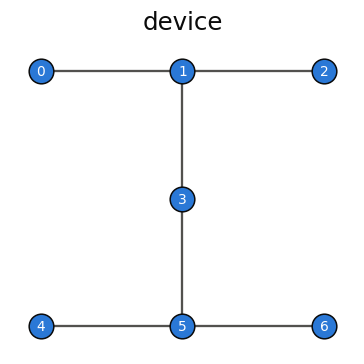

In [11]:
coupling_map = [
    (0, 1), (1, 0), (1, 2), (2, 1), (1, 3), (3, 1),
    (3, 5), (5, 3), (4, 5), (5, 4), (5, 6), (6, 5),
]
device = Topology.from_device(coupling_map)
print(device.edges)

fig, ax = plt.subplots(figsize=(3.2, 3.2))
draw(device, ax, pos={0: (0, 2), 1: (1, 2), 2: (2, 2), 3: (1, 1), 4: (0, 0), 5: (1, 0), 6: (2, 0)})
ax.set_title("device")
plt.show()

A circuit runs on the device without routing when every pair it couples is a coupling of the device, that is when `ansatz.topology.is_subgraph_of(device)`. Built on the device graph, or on any part of it, the ansatz fits. Built on a chain $0-1-2-3-4-5-6$, it does not: the chip has no $(2, 3)$ or $(3, 4)$, and a compiler would have to add SWAP gates.

In [12]:
candidates = {
    "device": device,
    "path 0-1-3-5-6": [(0, 1), (1, 3), (3, 5), (5, 6)],
    "chain": "chain",
}
for label, graph in candidates.items():
    ansatz = RampedKickedIsing(nqubits=7, n_steps=2, delta_h=0.2, graph=graph)
    print(f"{label:>15}: fits the device = {ansatz.topology.is_subgraph_of(device)}")

         device: fits the device = True
 path 0-1-3-5-6: fits the device = True
          chain: fits the device = False


The path leaves qubits 2 and 4 without couplings: they only get single-qubit gates. That is allowed, and `ansatz.topology.is_connected()` tells you when it happens.

## Summary

- A `Topology` is an ordered list of edges on the qubits; build it by name, from edges, from a graph or from a device coupling map.
- Every ansatz with couplings takes it through `graph`, and `ansatz.topology` reads back the pairs the circuit couples.
- At fixed magic, the graph sets how fast the MPS of HSMPO grows.
- Built on the coupling map of a device, or on part of it, the circuit runs without routing: check it with `is_subgraph_of`.